In [ ]:
!pip install xgboost -q

In [ ]:
import shutil
shutil.copy("final dataset.csv", "battery_full_dataset_12col.csv")

'battery_full_dataset_12col.csv'

In [ ]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

IN_PATH = "battery_full_dataset_12col.csv"
OUT_DIR = Path("processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

report_lines = []

def log(msg):
    print(msg)
    report_lines.append(str(msg))

# 1. LOAD + CLEAN
df = pd.read_csv(IN_PATH)
log(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

nulls = df.isnull().sum().sum()
dupes = df.duplicated().sum()
log(f"Missing values found: {nulls}")
log(f"Duplicate rows found: {dupes}")

df = df.drop_duplicates()
df = df.dropna()

before = len(df)
df = df[(df['voltage'] > 0) & (df['capacity'] > 0) & (df['soh'] >= 0) & (df['soh'] <= 1.2)]
log(f"Rows removed by physical-range sanity checks: {before - len(df)}")

df = df.sort_values(['battery_id', 'cycle']).reset_index(drop=True)

# 2. FEATURE ENGINEERING
log("\n--- Feature engineering ---")
df['capacity_fade_rate'] = df.groupby('battery_id')['capacity'].diff().fillna(0)
df['rolling_avg_temperature'] = (
    df.groupby('battery_id')['temperature']
      .transform(lambda s: s.rolling(window=5, min_periods=1).mean())
)
df['temp_gap'] = df['temperature'] - df['ambient_temperature']
max_cycle_per_batt = df.groupby('battery_id')['cycle'].transform('max')
df['cycle_pct'] = df['cycle'] / max_cycle_per_batt
log("Added: capacity_fade_rate, rolling_avg_temperature, temp_gap, cycle_pct")

# 3. ENCODE CATEGORICAL COLUMNS
log("\n--- Encoding categorical columns ---")
df['charging_mode_encoded'] = df['charging_mode'].map({'Slow': 0, 'Fast': 1})
risk_order = {'Safe': 0, 'Medium': 1, 'High': 2}
df['thermal_risk_encoded'] = df['thermal_risk'].map(risk_order)
label_encoders = {'charging_mode': {'Slow': 0, 'Fast': 1}, 'thermal_risk': risk_order}

# 4. BATTERY-WISE TRAIN/TEST SPLIT
log("\n--- Train/test split (by battery_id, not by row) ---")
battery_counts = df['battery_id'].value_counts()
usable_batteries = battery_counts[battery_counts >= 10].index.tolist()
tiny_batteries = battery_counts[battery_counts < 10].index.tolist()
log(f"Batteries with >=10 cycles (used for split): {len(usable_batteries)}")
log(f"Batteries with <10 cycles (excluded): {len(tiny_batteries)}")
log(f"  Excluded battery_ids: {tiny_batteries}")

rng = np.random.RandomState(RANDOM_STATE)
shuffled = rng.permutation(usable_batteries)
split_idx = int(len(shuffled) * 0.8)
train_batteries = set(shuffled[:split_idx])
test_batteries = set(shuffled[split_idx:])

train_df = df[df['battery_id'].isin(train_batteries)].reset_index(drop=True)
test_df = df[df['battery_id'].isin(test_batteries)].reset_index(drop=True)

log(f"Train batteries ({len(train_batteries)}): {sorted(train_batteries)}")
log(f"Test batteries  ({len(test_batteries)}): {sorted(test_batteries)}")
log(f"Train rows: {len(train_df)} | Test rows: {len(test_df)}")

train_df.to_csv(OUT_DIR / "train.csv", index=False)
test_df.to_csv(OUT_DIR / "test.csv", index=False)

# 5. SCALING
log("\n--- Scaling numeric features ---")
numeric_features = [
    'voltage', 'temperature', 'capacity', 'soc', 'current',
    'ambient_temperature', 'capacity_fade_rate', 'rolling_avg_temperature',
    'temp_gap'
]
scaler = StandardScaler()
train_scaled = train_df.copy()
test_scaled = test_df.copy()
train_scaled[numeric_features] = scaler.fit_transform(train_df[numeric_features])
test_scaled[numeric_features] = scaler.transform(test_df[numeric_features])
log(f"Scaled columns: {numeric_features}")

train_scaled.to_csv(OUT_DIR / "train_scaled.csv", index=False)
test_scaled.to_csv(OUT_DIR / "test_scaled.csv", index=False)

with open(OUT_DIR / "scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
with open(OUT_DIR / "label_encoders.pkl", "wb") as f:
    pickle.dump(label_encoders, f)

log("Saved: train_scaled.csv, test_scaled.csv, scaler.pkl, label_encoders.pkl")

# 6. LSTM SEQUENCES
log("\n--- Building LSTM sequences (for RUL / Module 2) ---")
SEQ_LEN = 10
seq_features = ['voltage', 'temperature', 'capacity', 'soh']

def build_sequences(frame, batteries, seq_len=SEQ_LEN):
    X, y, ids = [], [], []
    for b in batteries:
        sub = frame[frame['battery_id'] == b].sort_values('cycle')
        vals = sub[seq_features].values
        rul_vals = sub['rul'].values
        if len(sub) <= seq_len:
            continue
        for i in range(len(sub) - seq_len):
            X.append(vals[i:i + seq_len])
            y.append(rul_vals[i + seq_len])
            ids.append(b)
    return np.array(X), np.array(y), np.array(ids)

X_train, y_train, ids_train = build_sequences(train_scaled, train_batteries)
X_test, y_test, ids_test = build_sequences(test_scaled, test_batteries)

log(f"Sequence length (window): {SEQ_LEN} cycles")
log(f"Train sequences: {X_train.shape} | Test sequences: {X_test.shape}")

np.savez(OUT_DIR / "lstm_sequences_train.npz", X=X_train, y=y_train, battery_id=ids_train)
np.savez(OUT_DIR / "lstm_sequences_test.npz", X=X_test, y=y_test, battery_id=ids_test)
log("Saved: lstm_sequences_train.npz, lstm_sequences_test.npz")

# 7. MODEL FEATURE/TARGET MAP
model_map = {
    "Module 1 - SOH (XGBoost)": {"features": ["voltage", "temperature", "cycle", "soc", "capacity_fade_rate"], "target": "soh"},
    "Module 2 - RUL (LSTM)": {"features": seq_features + [f"(sequence window={SEQ_LEN})"], "target": "rul"},
    "Module 3 - Thermal Risk": {"features": ["temperature", "current", "ambient_temperature", "temp_gap"], "target": "thermal_risk_encoded"},
    "Module 4 - Smart Charging": {"features": ["soc", "soh", "charging_mode_encoded", "temperature"], "target": "charging_recommendation (derived rule)"},
    "Module 5 - Digital Twin": {"features": ["cycle", "capacity", "soh", "rul"], "target": "simulated future soh/rul"}
}
with open(OUT_DIR / "model_feature_map.json", "w") as f:
    json.dump(model_map, f, indent=2)

with open(OUT_DIR / "preprocessing_report.txt", "w") as f:
    f.write("\n".join(report_lines))

log(f"\nAll processed files written to: {OUT_DIR}")

Loaded dataset: 1415 rows, 12 columns
Missing values found: 0
Duplicate rows found: 0
Rows removed by physical-range sanity checks: 0

--- Feature engineering ---
Added: capacity_fade_rate, rolling_avg_temperature, temp_gap, cycle_pct

--- Encoding categorical columns ---

--- Train/test split (by battery_id, not by row) ---
Batteries with >=10 cycles (used for split): 21
Batteries with <10 cycles (excluded): 13
  Excluded battery_ids: ['B0049', 'B0025', 'B0033', 'B0050', 'B0040', 'B0036', 'B0038', 'B0034', 'B0051', 'B0052', 'B0054', 'B0055', 'B0056']
Train batteries (16): [np.str_('B0005'), np.str_('B0006'), np.str_('B0007'), np.str_('B0018'), np.str_('B0026'), np.str_('B0028'), np.str_('B0029'), np.str_('B0030'), np.str_('B0031'), np.str_('B0039'), np.str_('B0041'), np.str_('B0042'), np.str_('B0043'), np.str_('B0045'), np.str_('B0048'), np.str_('B0053')]
Test batteries  (5): [np.str_('B0027'), np.str_('B0032'), np.str_('B0044'), np.str_('B0046'), np.str_('B0047')]
Train rows: 1140 | 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("battery_full_dataset_12col.csv")

print("Shape:", df.shape)
print("\nColumn info:")
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nSummary statistics:")
print(df.describe())

Shape: (1415, 12)

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1415 entries, 0 to 1414
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   battery_id           1415 non-null   object 
 1   cycle                1415 non-null   int64  
 2   voltage              1415 non-null   float64
 3   temperature          1415 non-null   float64
 4   capacity             1415 non-null   float64
 5   soh                  1415 non-null   float64
 6   rul                  1415 non-null   int64  
 7   soc                  1415 non-null   float64
 8   current              1415 non-null   float64
 9   ambient_temperature  1415 non-null   float64
 10  charging_mode        1415 non-null   object 
 11  thermal_risk         1415 non-null   object 
dtypes: float64(7), int64(2), object(3)
memory usage: 132.8+ KB
None

Missing values:
 battery_id             0
cycle                  0
voltage                0

In [ ]:
print("Number of unique batteries:", df['battery_id'].nunique())
print("\nRows per battery:")
print(df['battery_id'].value_counts())

print("\nCharging mode distribution:")
print(df['charging_mode'].value_counts())

print("\nThermal risk distribution:")
print(df['thermal_risk'].value_counts())

Number of unique batteries: 34

Rows per battery:
battery_id
B0005    168
B0007    168
B0006    155
B0018    132
B0042     99
B0045     70
B0047     69
B0046     69
B0048     69
B0043     66
B0044     66
B0053     45
B0030     34
B0029     32
B0032     29
B0028     27
B0041     25
B0031     21
B0026     18
B0027     14
B0039     11
B0049      8
B0025      5
B0033      3
B0050      2
B0040      2
B0036      1
B0038      1
B0034      1
B0051      1
B0052      1
B0054      1
B0055      1
B0056      1
Name: count, dtype: int64

Charging mode distribution:
charging_mode
Slow    1101
Fast     314
Name: count, dtype: int64

Thermal risk distribution:
thermal_risk
Medium    660
Safe      638
High      117
Name: count, dtype: int64


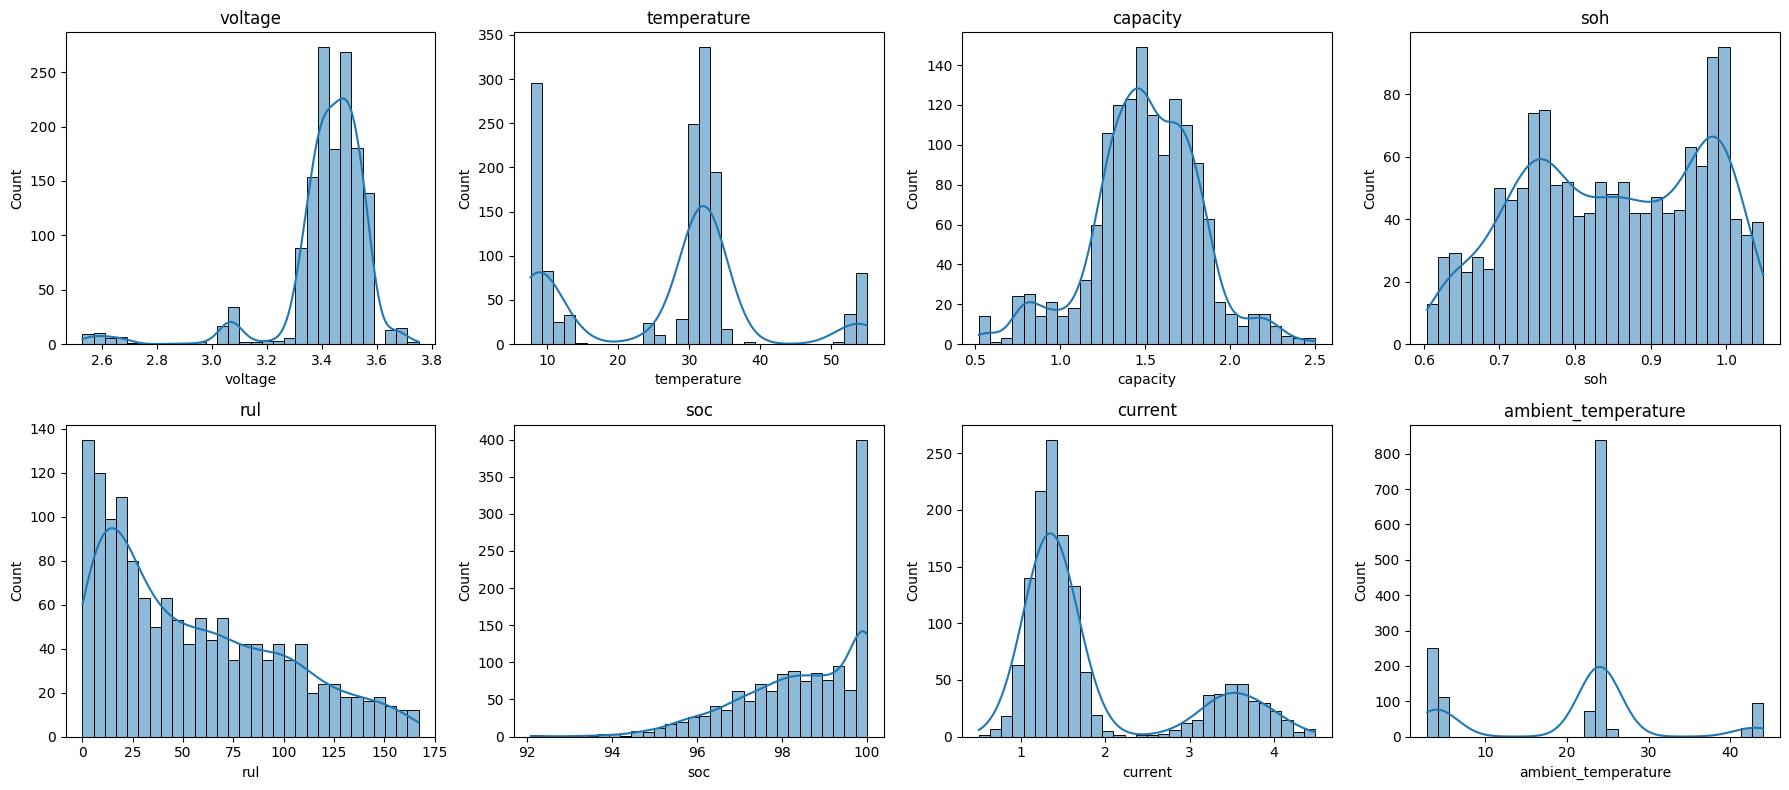

In [ ]:
num_cols = ['voltage', 'temperature', 'capacity', 'soh', 'rul', 'soc', 'current', 'ambient_temperature']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, col in enumerate(num_cols):
    ax = axes[i // 4, i % 4]
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("eda_distributions.png", dpi=150)
plt.show()

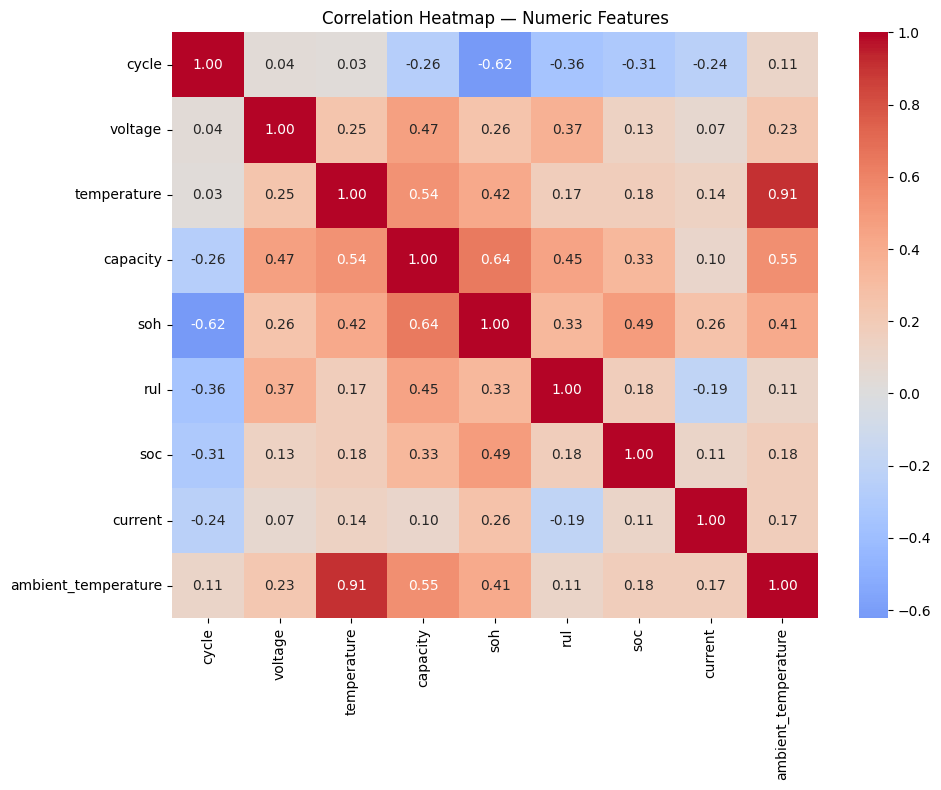


Strongest correlations with SOH:
soh                    1.000000
capacity               0.643486
soc                    0.485638
temperature            0.418583
ambient_temperature    0.405280
rul                    0.332720
current                0.259917
voltage                0.257508
cycle                 -0.622161
Name: soh, dtype: float64

Strongest correlations with RUL:
rul                    1.000000
capacity               0.448028
voltage                0.368511
soh                    0.332720
soc                    0.175011
temperature            0.174537
ambient_temperature    0.113217
current               -0.193346
cycle                 -0.355340
Name: rul, dtype: float64


In [ ]:
plt.figure(figsize=(10, 8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.savefig("eda_correlation_heatmap.png", dpi=150)
plt.show()

print("\nStrongest correlations with SOH:")
print(corr['soh'].sort_values(ascending=False))
print("\nStrongest correlations with RUL:")
print(corr['rul'].sort_values(ascending=False))

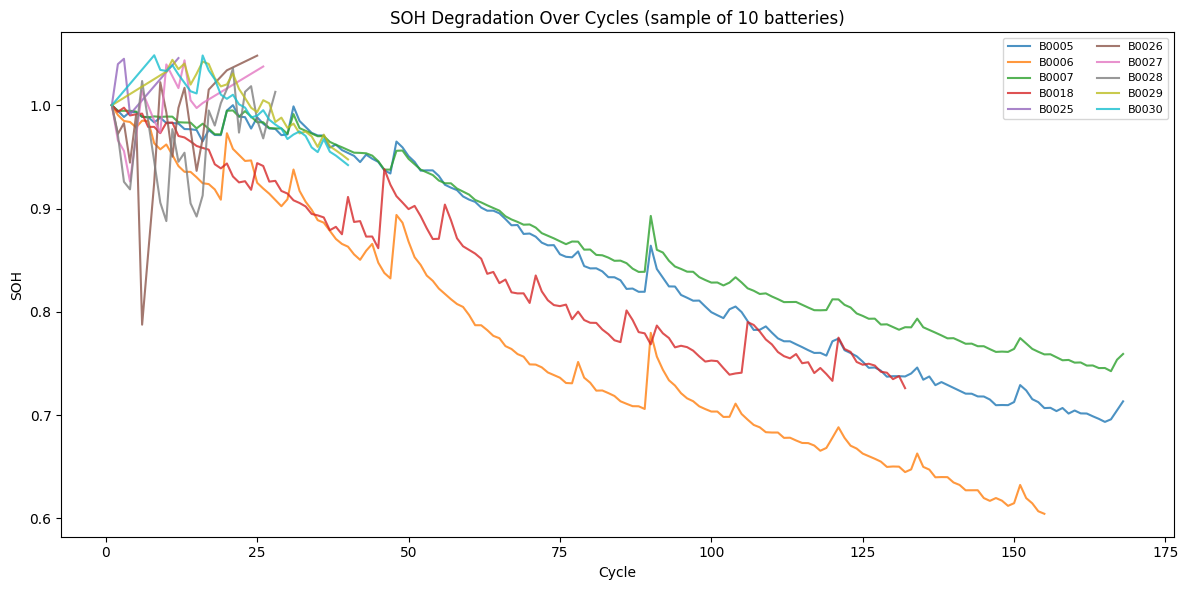

In [ ]:
plt.figure(figsize=(12, 6))
for b in df['battery_id'].unique()[:10]:  # first 10 batteries, to keep it readable
    sub = df[df['battery_id'] == b].sort_values('cycle')
    plt.plot(sub['cycle'], sub['soh'], label=b, alpha=0.8)
plt.xlabel("Cycle")
plt.ylabel("SOH")
plt.title("SOH Degradation Over Cycles (sample of 10 batteries)")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig("eda_soh_degradation.png", dpi=150)
plt.show()

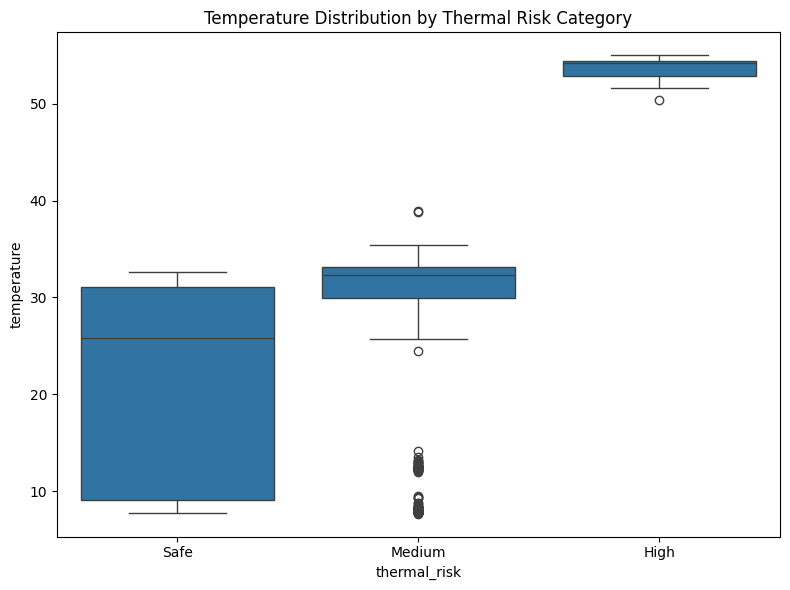

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='thermal_risk', y='temperature', order=['Safe', 'Medium', 'High'])
plt.title("Temperature Distribution by Thermal Risk Category")
plt.tight_layout()
plt.savefig("eda_temp_vs_risk.png", dpi=150)
plt.show()

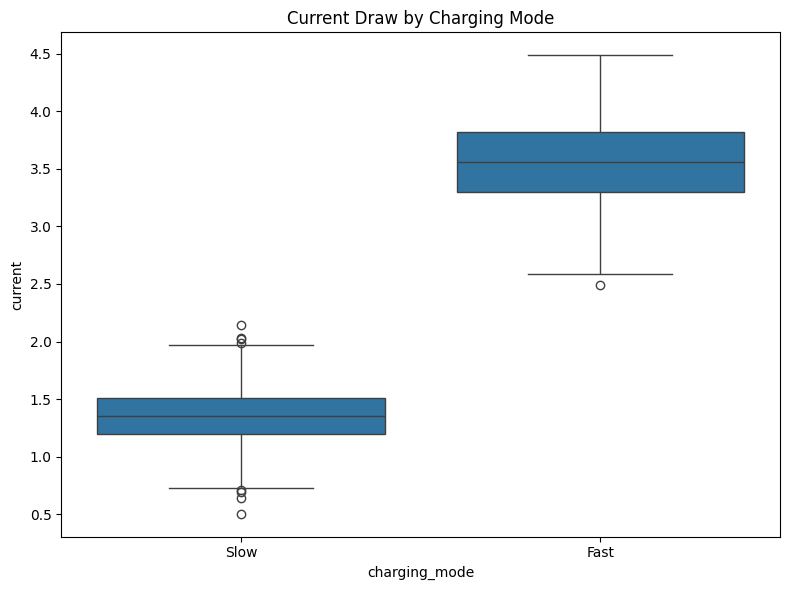

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='charging_mode', y='current')
plt.title("Current Draw by Charging Mode")
plt.tight_layout()
plt.savefig("eda_current_vs_chargingmode.png", dpi=150)
plt.show()

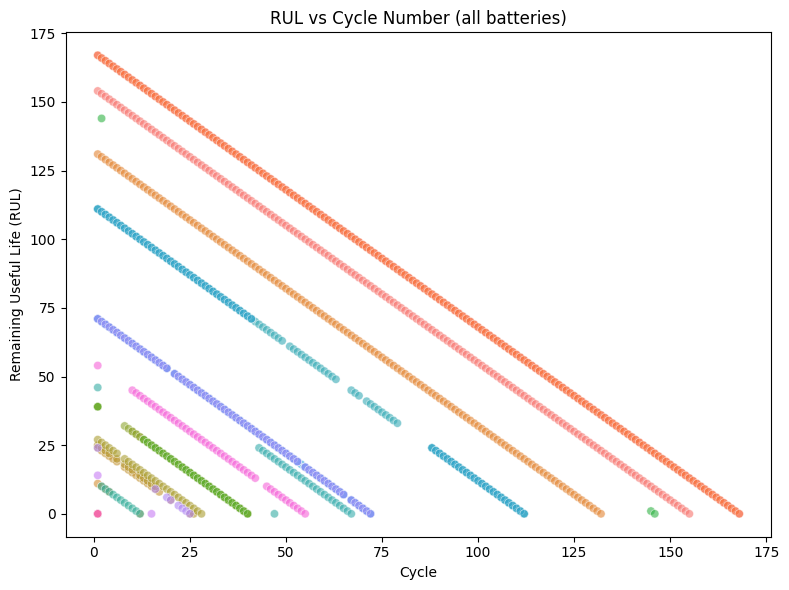

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='cycle', y='rul', hue='battery_id', legend=False, alpha=0.6)
plt.xlabel("Cycle")
plt.ylabel("Remaining Useful Life (RUL)")
plt.title("RUL vs Cycle Number (all batteries)")
plt.tight_layout()
plt.savefig("eda_rul_vs_cycle.png", dpi=150)
plt.show()

In [ ]:
import pandas as pd
import pickle
from pathlib import Path
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("processed")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

FEATURES = ['voltage', 'temperature', 'cycle', 'soc', 'capacity_fade_rate']
TARGET = 'soh'

train = pd.read_csv(DATA_DIR / "train_scaled.csv")
test = pd.read_csv(DATA_DIR / "test_scaled.csv")

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

model = XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                      subsample=0.9, colsample_bytree=0.9, random_state=42)
model.fit(X_train, y_train)
preds = model.predict(X_test)

mae = mean_absolute_error(y_test, preds)
rmse = mean_squared_error(y_test, preds) ** 0.5
r2 = r2_score(y_test, preds)

print("MODULE 1 — SOH PREDICTION (XGBoost)")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")
print("\nFeature importance:")
for feat, imp in sorted(zip(FEATURES, model.feature_importances_), key=lambda x: -x[1]):
    print(f"  {feat:25s} {imp:.4f}")

with open(MODEL_DIR / "model1_soh_xgboost.pkl", "wb") as f:
    pickle.dump(model, f)
print(f"\nSaved model to {MODEL_DIR / 'model1_soh_xgboost.pkl'}")

MODULE 1 — SOH PREDICTION (XGBoost)
MAE  : 0.0397
RMSE : 0.0476
R2   : 0.8183

Feature importance:
  cycle                     0.4045
  voltage                   0.2504
  temperature               0.2115
  soc                       0.1102
  capacity_fade_rate        0.0233

Saved model to models/model1_soh_xgboost.pkl


In [ ]:
import numpy as np
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)
tf.random.set_seed(42)

DATA_DIR = Path("processed")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

train_data = np.load(DATA_DIR / "lstm_sequences_train.npz", allow_pickle=True)
test_data = np.load(DATA_DIR / "lstm_sequences_test.npz", allow_pickle=True)

X_train, y_train_raw = train_data['X'], train_data['y']
X_test, y_test = test_data['X'], test_data['y']

print("MODULE 2 — RUL PREDICTION (LSTM)")
print(f"Train sequences: {X_train.shape} | Test sequences: {X_test.shape}")

y_max = y_train_raw.max()
y_train = y_train_raw / y_max

n_timesteps = X_train.shape[1]
n_features = X_train.shape[2]

model = keras.Sequential([
    layers.Input(shape=(n_timesteps, n_features)),
    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005), loss='mse', metrics=['mae'])

early_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True, min_delta=1e-4)

history = model.fit(X_train, y_train, validation_split=0.15, epochs=150,
                     batch_size=16, callbacks=[early_stop], verbose=0)

preds_scaled = model.predict(X_test, verbose=0).flatten()
preds = preds_scaled * y_max

mae = mean_absolute_error(y_test, preds)
rmse = mean_squared_error(y_test, preds) ** 0.5
r2 = r2_score(y_test, preds)

print(f"Epochs actually run: {len(history.history['loss'])}")
print(f"MAE  : {mae:.2f} cycles")
print(f"RMSE : {rmse:.2f} cycles")
print(f"R2   : {r2:.4f}")

model.save(MODEL_DIR / "model2_rul_lstm.keras")
print(f"\nSaved model to {MODEL_DIR / 'model2_rul_lstm.keras'}")

print("\nSample predictions vs actual (first 5):")
for i in range(min(5, len(preds))):
    print(f"  Predicted RUL: {preds[i]:.1f}   Actual RUL: {y_test[i]}")

MODULE 2 — RUL PREDICTION (LSTM)
Train sequences: (980, 10, 4) | Test sequences: (197, 10, 4)
Epochs actually run: 21
MAE  : 18.07 cycles
RMSE : 22.04 cycles
R2   : 0.3758

Saved model to models/model2_rul_lstm.keras

Sample predictions vs actual (first 5):
  Predicted RUL: 17.9   Actual RUL: 61
  Predicted RUL: 16.9   Actual RUL: 60
  Predicted RUL: 16.7   Actual RUL: 59
  Predicted RUL: 16.7   Actual RUL: 58
  Predicted RUL: 16.6   Actual RUL: 57


In [ ]:
import pandas as pd
import pickle
from pathlib import Path
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

DATA_DIR = Path("processed")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

FEATURES = ['temperature', 'current', 'ambient_temperature', 'temp_gap']
TARGET = 'thermal_risk_encoded'
LABELS = {0: 'Safe', 1: 'Medium', 2: 'High'}

train = pd.read_csv(DATA_DIR / "train_scaled.csv")
test = pd.read_csv(DATA_DIR / "test_scaled.csv")

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

model = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=42, eval_metric='mlogloss')
model.fit(X_train, y_train)
preds = model.predict(X_test)

print("MODULE 3 — THERMAL RISK CLASSIFICATION")
print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
print(classification_report(y_test, preds, target_names=[LABELS[i] for i in sorted(LABELS)]))
print(pd.DataFrame(confusion_matrix(y_test, preds),
                    index=[f"actual_{LABELS[i]}" for i in sorted(LABELS)],
                    columns=[f"pred_{LABELS[i]}" for i in sorted(LABELS)]))

with open(MODEL_DIR / "model3_thermal_risk.pkl", "wb") as f:
    pickle.dump(model, f)
print("Saved model.")

MODULE 3 — THERMAL RISK CLASSIFICATION
Accuracy: 0.9960
              precision    recall  f1-score   support

        Safe       1.00      0.99      1.00       188
      Medium       0.97      1.00      0.98        30
        High       1.00      1.00      1.00        29

    accuracy                           1.00       247
   macro avg       0.99      1.00      0.99       247
weighted avg       1.00      1.00      1.00       247

               pred_Safe  pred_Medium  pred_High
actual_Safe          187            1          0
actual_Medium          0           30          0
actual_High            0            0         29
Saved model.


In [ ]:
# ============================================================
# MODULE 4 - SMART CHARGING RECOMMENDATION SYSTEM
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

print("="*70)
print("MODULE 4 - SMART CHARGING RECOMMENDATION SYSTEM")
print("="*70)

# ------------------------------------------------------------
# Rule Engine
# ------------------------------------------------------------

def charging_rule(soc, soh, temperature, charging_mode):

    # Battery too hot
    if temperature >= 45:
        return "STOP CHARGING"

    # Battery almost full
    elif soc >= 80:
        return "STOP CHARGING"

    # Battery health poor
    elif soh < 0.75:
        return "CHARGE SLOW"

    # Fast charging at high temperature
    elif charging_mode == "Fast" and temperature >= 35:
        return "SWITCH TO SLOW CHARGING"

    # Battery almost empty
    elif soc <= 20 and temperature < 35:
        return "FAST CHARGING ALLOWED"

    elif soc <= 20 and temperature >= 35:
        return "CHARGE SLOW"

    else:
        return "CONTINUE NORMAL CHARGING"


# ------------------------------------------------------------
# Create recommendation labels
# ------------------------------------------------------------

train["charging_recommendation"] = train.apply(
    lambda row: charging_rule(
        row["soc"],
        row["soh"],
        row["temperature"],
        row["charging_mode"]
    ),
    axis=1
)

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------

features = [
    "soc",
    "soh",
    "temperature",
    "voltage",
    "current",
    "capacity"
]

X = train[features]

label_enc = LabelEncoder()

y = label_enc.fit_transform(train["charging_recommendation"])

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# ------------------------------------------------------------
# Train Decision Tree
# ------------------------------------------------------------

model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

model.fit(X_train,y_train)

preds = model.predict(X_test)

print("\nAccuracy :",accuracy_score(y_test,preds))

print(classification_report(
    y_test,
    preds,
    target_names=label_enc.classes_,
    zero_division=0
))

# ------------------------------------------------------------
# Recommendation Results
# ------------------------------------------------------------

results = X_test.copy()

results["Recommendation"] = label_enc.inverse_transform(preds)

results["Actual"] = label_enc.inverse_transform(y_test)

# ------------------------------------------------------------
# Explain recommendations
# ------------------------------------------------------------

def explain(row):

    if row["Recommendation"]=="STOP CHARGING":

        if row["temperature"]>=45:
            return "Battery temperature is very high. Stop charging immediately."

        return "Battery is almost fully charged. Stop charging."

    elif row["Recommendation"]=="CHARGE SLOW":
        return "Battery health is degraded. Slow charging is recommended."

    elif row["Recommendation"]=="SWITCH TO SLOW CHARGING":
        return "Fast charging with high temperature detected."

    elif row["Recommendation"]=="FAST CHARGING ALLOWED":
        return "Battery charge is low and temperature is safe."

    else:
        return "Battery condition is normal."

results["Reason"] = results.apply(explain,axis=1)

print("\n")
print("="*80)
print("SMART CHARGING RECOMMENDATIONS")
print("="*80)

print(results[[
    "soc",
    "soh",
    "temperature",
    "voltage",
    "current",
    "capacity",
    "Recommendation",
    "Reason"
]].head(20))

MODULE 4 - SMART CHARGING RECOMMENDATION SYSTEM

Accuracy : 1.0
                       precision    recall  f1-score   support

          CHARGE SLOW       1.00      1.00      1.00        54
FAST CHARGING ALLOWED       1.00      1.00      1.00       174

             accuracy                           1.00       228
            macro avg       1.00      1.00      1.00       228
         weighted avg       1.00      1.00      1.00       228



SMART CHARGING RECOMMENDATIONS
           soc       soh  temperature   voltage   current  capacity  \
788  -0.872925  0.729147    -1.629483 -0.413957  2.193641 -1.749926   
904   1.043576  0.935344     0.115923  0.392747  1.551080  0.322827   
289  -0.679199  0.677998     0.493634 -0.098712 -0.820573 -0.387863   
1040  1.043576  0.847120    -1.710236  0.070500  1.677929 -0.359924   
332   1.043576  0.989036     0.343277  0.641819 -0.599108  1.207029   
109  -0.831412  0.779867     0.456276  0.383670 -0.418193 -0.214050   
526   1.043576  0.891394 

In [ ]:
print(df.columns)

Index(['battery_id', 'cycle', 'voltage', 'temperature', 'capacity', 'soh',
       'rul', 'soc', 'current', 'ambient_temperature', 'charging_mode',
       'thermal_risk'],
      dtype='object')


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = Path("processed")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")

WINDOW = 20
REFIT_EVERY = 10

def fit_recent_slope(hist_df):
    recent = hist_df.tail(WINDOW)
    if len(recent) < 2:
        recent = hist_df
    slope, intercept = np.polyfit(recent['cycle'], recent['soh'], 1)
    return slope

def build_slope_schedule(battery_id, n_future_cycles=30):
    """Base (unstressed) slope trajectory, shared by every scenario — never
    refit from its own generated output, so it can't compound or wobble."""
    hist = train[train['battery_id'] == battery_id].sort_values('cycle')
    working_hist = hist[['cycle', 'soh']].copy()
    last_cycle = int(hist['cycle'].max())
    soh = hist['soh'].iloc[-1]

    slope = fit_recent_slope(working_hist)
    schedule = []
    for step in range(1, n_future_cycles + 1):
        schedule.append(slope)
        cycle = last_cycle + step
        soh = max(0.0, soh + slope)
        working_hist = pd.concat([working_hist,
                                   pd.DataFrame([{'cycle': cycle, 'soh': soh}])],
                                  ignore_index=True)
        if step % REFIT_EVERY == 0:
            slope = fit_recent_slope(working_hist)
    return schedule

def simulate_future(battery_id, slope_schedule, charging_stress="normal"):
    hist = train[train['battery_id'] == battery_id].sort_values('cycle')
    last_cycle = int(hist['cycle'].max())
    soh = hist['soh'].iloc[-1]
    stress_multiplier = 2.2 if charging_stress == "fast_daily" else 1.0

    rows = []
    for step, base_slope in enumerate(slope_schedule, start=1):
        cycle = last_cycle + step
        soh = max(0.0, soh + base_slope * stress_multiplier)
        rows.append({'battery_id': battery_id, 'cycle': cycle,
                     'predicted_soh': round(soh, 4), 'scenario': charging_stress})
    return pd.DataFrame(rows)

battery_id = train['battery_id'].value_counts().index[0]
print(f"MODULE 5 — DIGITAL TWIN SIMULATION (battery {battery_id})")

slope_schedule = build_slope_schedule(battery_id, n_future_cycles=30)
normal_sim = simulate_future(battery_id, slope_schedule, "normal")
stress_sim = simulate_future(battery_id, slope_schedule, "fast_daily")

print("\nNormal usage (every 5th cycle):")
print(normal_sim.iloc[4::5].to_string(index=False))
print("\nFast-charging stress (every 5th cycle):")
print(stress_sim.iloc[4::5].to_string(index=False))

drop_normal = normal_sim.iloc[0]['predicted_soh'] - normal_sim.iloc[-1]['predicted_soh']
drop_stress = stress_sim.iloc[0]['predicted_soh'] - stress_sim.iloc[-1]['predicted_soh']
print(f"\nSOH drop (normal): {drop_normal:.4f} | SOH drop (fast charging): {drop_stress:.4f}")
print(f"-> Fast charging degrades ~{drop_stress/drop_normal:.1f}x faster")

pd.concat([normal_sim, stress_sim]).to_csv(MODEL_DIR / f"digital_twin_{battery_id}.csv", index=False)

MODULE 5 — DIGITAL TWIN SIMULATION (battery B0005)

Normal usage (every 5th cycle):
battery_id  cycle  predicted_soh scenario
     B0005    173         0.7082   normal
     B0005    178         0.7031   normal
     B0005    183         0.7051   normal
     B0005    188         0.7071   normal
     B0005    193         0.7059   normal
     B0005    198         0.7046   normal

Fast-charging stress (every 5th cycle):
battery_id  cycle  predicted_soh   scenario
     B0005    173         0.7021 fast_daily
     B0005    178         0.6908 fast_daily
     B0005    183         0.6953 fast_daily
     B0005    188         0.6997 fast_daily
     B0005    193         0.6969 fast_daily
     B0005    198         0.6941 fast_daily

SOH drop (normal): 0.0077 | SOH drop (fast charging): 0.0170
-> Fast charging degrades ~2.2x faster


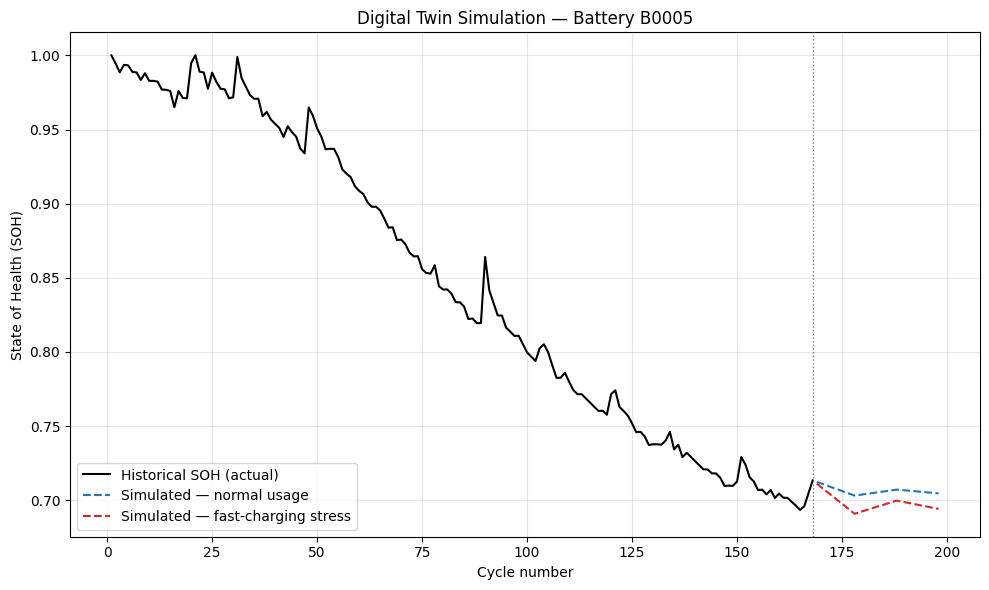

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt

hist = train[train['battery_id'] == battery_id].sort_values('cycle')

plt.figure(figsize=(10, 6))
plt.plot(hist['cycle'], hist['soh'], color='black', linewidth=1.5, label='Historical SOH (actual)')
plt.plot(normal_sim['cycle'], normal_sim['predicted_soh'], '--', color='tab:blue', linewidth=1.5, label='Simulated — normal usage')
plt.plot(stress_sim['cycle'], stress_sim['predicted_soh'], '--', color='tab:red', linewidth=1.5, label='Simulated — fast-charging stress')
plt.axvline(hist['cycle'].max(), color='gray', linestyle=':', linewidth=1)
plt.xlabel('Cycle number')
plt.ylabel('State of Health (SOH)')
plt.title(f'Digital Twin Simulation — Battery {battery_id}')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('digital_twin_plot.png', dpi=200)
plt.show()

from google.colab import files
files.download('digital_twin_plot.png')

In [ ]:
# ============================================================
# 🔋 DIGITAL TWIN
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
import ipywidgets as widgets

# ------------------------------------------------------------
# 1. FIND YOUR UPLOADED CSV AUTOMATICALLY
# ------------------------------------------------------------

csv_files = glob.glob("/content/*.csv")

print("CSV files found:")

for f in csv_files:
    print("  ", f)

if len(csv_files) == 0:
    raise FileNotFoundError(
        "No CSV file found. Please upload your dataset first."
    )

# Automatically select the first CSV
DATA_FILE = csv_files[0]

print("\nUsing dataset:")
print(DATA_FILE)

# ------------------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(DATA_FILE)

print("\nDataset loaded successfully!")
print("Rows:", len(df))
print("Columns:")
print(df.columns.tolist())

# ------------------------------------------------------------
# 3. CHECK BATTERY COLUMN
# ------------------------------------------------------------

df["battery_id"] = df["battery_id"].astype(str)

print("\nBatteries available:")
print(df["battery_id"].unique())

# ------------------------------------------------------------
# 4. SELECT B0005
# ------------------------------------------------------------

battery_id = "B0005"

battery = (
    df[df["battery_id"] == battery_id]
    .sort_values("cycle")
    .reset_index(drop=True)
)

if battery.empty:
    raise ValueError(
        "B0005 was not found in your dataset."
    )

latest = battery.iloc[-1]

print("\n" + "=" * 60)
print("PHYSICAL BATTERY SELECTED:", battery_id)
print("=" * 60)

print("Latest cycle:", latest["cycle"])
print("SOH:", latest["soh"])
print("SOC:", latest["soc"])
print("Voltage:", latest["voltage"])
print("Temperature:", latest["temperature"])
print("Current:", latest["current"])
print("RUL:", latest["rul"])

# ------------------------------------------------------------
# 5. DIGITAL TWIN CLASS
# ------------------------------------------------------------

class BatteryDigitalTwin:

    def __init__(self, physical_state):

        self.battery_id = physical_state["battery_id"]

        self.cycle = int(
            physical_state["cycle"]
        )

        self.soh = float(
            physical_state["soh"]
        )

        self.soc = float(
            physical_state["soc"]
        )

        self.voltage = float(
            physical_state["voltage"]
        )

        self.temperature = float(
            physical_state["temperature"]
        )

        self.current = float(
            physical_state["current"]
        )

        self.rul = float(
            physical_state["rul"]
        )

        self.capacity = float(
            physical_state["capacity"]
        )

        self.ambient_temperature = float(
            physical_state["ambient_temperature"]
        )

        self.charging_mode = str(
            physical_state["charging_mode"]
        )

        self.thermal_risk = str(
            physical_state["thermal_risk"]
        )

    # --------------------------------------------------------
    # UPDATE VIRTUAL BATTERY
    # --------------------------------------------------------

    def simulate(
        self,
        charging_mode,
        ambient_temperature,
        current,
        target_soc,
        future_cycles
    ):

        # Charging stress
        if charging_mode == "Slow":
            charging_factor = 1.0
        else:
            charging_factor = 2.2

        # Temperature stress
        if ambient_temperature <= 30:
            temperature_factor = 1.0

        elif ambient_temperature <= 35:
            temperature_factor = 1.15

        elif ambient_temperature <= 40:
            temperature_factor = 1.45

        else:
            temperature_factor = 1.90

        # Current stress
        current_factor = max(
            0.75,
            current / 2.0
        )

        # Combined stress
        stress_factor = (
            charging_factor
            * temperature_factor
            * current_factor
        )

        # ----------------------------------------------------
        # Estimate SOH degradation
        # ----------------------------------------------------

        recent = battery.tail(20)

        if len(recent) >= 2:

            slope = np.polyfit(
                recent["cycle"],
                recent["soh"],
                1
            )[0]

            base_degradation = abs(
                float(slope)
            )

        else:

            base_degradation = 0.001

        base_degradation = np.clip(
            base_degradation,
            0.0002,
            0.01
        )

        # ----------------------------------------------------
        # SOH
        # ----------------------------------------------------

        soh_loss = (
            base_degradation
            * stress_factor
            * future_cycles
        )

        self.soh = max(
            0,
            self.soh - soh_loss
        )

        # ----------------------------------------------------
        # SOC
        # ----------------------------------------------------

        self.soc = np.clip(
            target_soc,
            0,
            100
        )

        # ----------------------------------------------------
        # Temperature
        # ----------------------------------------------------

        self.temperature = (
            ambient_temperature
            + 5
            + 0.8 * current
            + (
                3
                if charging_mode == "Fast"
                else 0
            )
        )

        # ----------------------------------------------------
        # Voltage
        # ----------------------------------------------------

        soc_effect = (
            self.soc - 50
        ) / 100

        health_effect = (
            self.soh - 0.7
        ) * 0.5

        self.voltage = (
            3.45
            + 0.20 * soc_effect
            + health_effect
        )

        # ----------------------------------------------------
        # RUL
        # ----------------------------------------------------

        rul_loss = (
            future_cycles
            * max(
                1,
                stress_factor
            )
        )

        self.rul = max(
            0,
            self.rul - rul_loss
        )

        # ----------------------------------------------------
        # Thermal risk
        # ----------------------------------------------------

        if self.temperature < 35:

            self.thermal_risk = "SAFE"

        elif self.temperature < 40:

            self.thermal_risk = "MEDIUM"

        elif self.temperature < 45:

            self.thermal_risk = "HIGH"

        else:

            self.thermal_risk = "CRITICAL"

        # ----------------------------------------------------
        # Other states
        # ----------------------------------------------------

        self.current = current

        self.charging_mode = charging_mode

        self.cycle += future_cycles

        return stress_factor


# ------------------------------------------------------------
# 6. CREATE VIRTUAL BATTERY
# ------------------------------------------------------------

twin = BatteryDigitalTwin(latest)

print("\nVirtual Battery Created Successfully!")

# ------------------------------------------------------------
# 7. INTERACTIVE CONTROLS
# ------------------------------------------------------------

charging = widgets.Dropdown(
    options=["Slow", "Fast"],
    value="Slow",
    description="Charging:"
)

temperature = widgets.IntSlider(
    value=25,
    min=15,
    max=50,
    step=1,
    description="Temperature:"
)

current = widgets.FloatSlider(
    value=2.0,
    min=0.5,
    max=6.0,
    step=0.1,
    description="Current:"
)

soc = widgets.IntSlider(
    value=80,
    min=50,
    max=100,
    step=1,
    description="Target SOC:"
)

cycles = widgets.IntSlider(
    value=10,
    min=1,
    max=30,
    step=1,
    description="Future Cycles:"
)

run_button = widgets.Button(
    description="🔄 RUN DIGITAL TWIN",
    button_style="success"
)

output = widgets.Output()

# ------------------------------------------------------------
# 8. BATTERY VISUAL
# ------------------------------------------------------------

def draw_battery(soh, risk):

    fig, ax = plt.subplots(
        figsize=(4,5)
    )

    ax.set_xlim(0,10)
    ax.set_ylim(0,12)

    # Battery body
    body = plt.Rectangle(
        (2,1),
        6,
        9,
        fill=False,
        linewidth=4
    )

    ax.add_patch(body)

    # Battery terminal
    terminal = plt.Rectangle(
        (4,10),
        2,
        0.8,
        fill=False,
        linewidth=4
    )

    ax.add_patch(terminal)

    # Battery level
    fill_height = (
        8.5 * np.clip(soh,0,1)
    )

    ax.add_patch(
        plt.Rectangle(
            (2.3,1.3),
            5.4,
            fill_height,
            alpha=0.6
        )
    )

    ax.text(
        5,
        5.5,
        f"{soh*100:.1f}%",
        ha="center",
        va="center",
        fontsize=22,
        fontweight="bold"
    )

    ax.text(
        5,
        0.3,
        f"Thermal Risk: {risk}",
        ha="center"
    )

    ax.set_title(
        "VIRTUAL BATTERY",
        fontsize=16,
        fontweight="bold"
    )

    ax.axis("off")

    plt.show()


# ------------------------------------------------------------
# 9. RUN DIGITAL TWIN
# ------------------------------------------------------------

def run_twin(button):

    with output:

        clear_output(wait=True)

        # Create fresh twin from actual physical battery
        virtual_battery = BatteryDigitalTwin(
            latest
        )

        stress = virtual_battery.simulate(
            charging_mode=charging.value,
            ambient_temperature=temperature.value,
            current=current.value,
            target_soc=soc.value,
            future_cycles=cycles.value
        )

        print("=" * 65)
        print("🔋 DIGITAL TWIN - VIRTUAL BATTERY")
        print("=" * 65)

        print(
            f"Battery ID       : {virtual_battery.battery_id}"
        )

        print(
            f"Simulation       : +{cycles.value} cycles"
        )

        print(
            f"Charging Mode    : {charging.value}"
        )

        print(
            f"Ambient Temp.    : {temperature.value} °C"
        )

        print(
            f"Current          : {current.value:.2f} A"
        )

        print(
            f"Target SOC       : {soc.value}%"
        )

        print("-" * 65)

        print(
            f"Virtual Cycle    : {virtual_battery.cycle}"
        )

        print(
            f"Virtual SOH      : "
            f"{virtual_battery.soh*100:.2f}%"
        )

        print(
            f"Virtual SOC      : "
            f"{virtual_battery.soc:.2f}%"
        )

        print(
            f"Virtual Voltage  : "
            f"{virtual_battery.voltage:.3f} V"
        )

        print(
            f"Virtual Temp.    : "
            f"{virtual_battery.temperature:.2f} °C"
        )

        print(
            f"Virtual Current  : "
            f"{virtual_battery.current:.2f} A"
        )

        print(
            f"Virtual RUL      : "
            f"{virtual_battery.rul:.0f} cycles"
        )

        print(
            f"Thermal Risk     : "
            f"{virtual_battery.thermal_risk}"
        )

        print("-" * 65)

        print(
            f"Battery Stress Factor: "
            f"{stress:.2f}"
        )

        print("=" * 65)

        # Draw virtual battery
        draw_battery(
            virtual_battery.soh,
            virtual_battery.thermal_risk
        )

        # Recommendation
        print("\n🤖 RECOMMENDATION")

        if virtual_battery.thermal_risk in [
            "HIGH",
            "CRITICAL"
        ]:

            print(
                "⚠️ Reduce charging current "
                "or operating temperature."
            )

        elif charging.value == "Fast":

            print(
                "⚠️ Fast charging increases "
                "simulated battery degradation."
            )

        elif current.value > 3:

            print(
                "⚠️ High current detected."
            )

        else:

            print(
                "✅ Battery operating conditions "
                "are relatively moderate."
            )


run_button.on_click(
    run_twin
)

# ------------------------------------------------------------
# 10. SHOW DASHBOARD
# ------------------------------------------------------------

display(
    widgets.VBox([
        widgets.HTML(
            "<h2>🔋 EV BATTERY DIGITAL TWIN</h2>"
        ),

        charging,
        temperature,
        current,
        soc,
        cycles,

        run_button,

        output
    ])
)

print(
    "\nChange the battery conditions and click "
    "'RUN DIGITAL TWIN'."
)

CSV files found:
   /content/battery_full_dataset_12col.csv
   /content/final dataset.csv

Using dataset:
/content/battery_full_dataset_12col.csv

Dataset loaded successfully!
Rows: 1415
Columns:
['battery_id', 'cycle', 'voltage', 'temperature', 'capacity', 'soh', 'rul', 'soc', 'current', 'ambient_temperature', 'charging_mode', 'thermal_risk']

Batteries available:
['B0005' 'B0006' 'B0007' 'B0018' 'B0025' 'B0026' 'B0027' 'B0028' 'B0029'
 'B0030' 'B0031' 'B0032' 'B0033' 'B0034' 'B0036' 'B0038' 'B0039' 'B0040'
 'B0041' 'B0042' 'B0043' 'B0044' 'B0045' 'B0046' 'B0047' 'B0048' 'B0049'
 'B0050' 'B0051' 'B0052' 'B0053' 'B0054' 'B0055' 'B0056']

PHYSICAL BATTERY SELECTED: B0005
Latest cycle: 168
SOH: 0.713327813
SOC: 98.02
Voltage: 3.475718827
Temperature: 33.64458842
Current: 1.416
RUL: 0

Virtual Battery Created Successfully!



Change the battery conditions and click 'RUN DIGITAL TWIN'.
